### Section 3: Measures of Position (Relative Standing)

While **central tendency** gives the middle and **dispersion** measures the spread, **measures of position** describe where a specific data point or value stands relative to the rest of the distribution.

Below are clear, naive examples covering the core measures of position, complete with mathematical formulas, notation pronunciations, and Python implementation comparisons across **Plain Python**, **Standard Library `statistics`**, and **`NumPy`** / **`SciPy`** / **`Matplotlib`**:
1. **Percentiles ($P_p$)**
2. **Quartiles ($Q_1, Q_2, Q_3$) & Interquartile Range (IQR)**
3. **Deciles ($D_1 \dots D_9$)**
4. **$Z$-Score / Standard Score ($z$)**
5. **Modified $Z$-Score (Robust Outlier Detection with MAD)**
6. **Percentile Rank (PR)**
7. **Summary Cheat Sheet & Decision Matrix**
---
---


### Setup


In [2]:
import statistics
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import math

# Set plot style
plt.style.use('seaborn_v0_8_white' if 'seaborn_v0_8_white' in plt.style.available else 'default')
plt.rcParams["figure.dpi"] = 100
np.random.seed(42)

print("Libraries imported successfully!")


Libraries imported successfully!


--- 
## 1. Percentiles (Division into 100 Equal Parts)

* **What it does:** Identifies the value below which a given percentage $p\%$ of observations fall.
* **Mathematical Notation:**
  $$P_p = x_{(k)}, \quad \text{where } k = \frac{p}{100} \times (n + 1)$$
  *Where:*
  * $P_p$ (*P sub p*): p-th percentile value
  * $p$ (*p*): Target percentile rank (e.g., 80 for 80th percentile)
  * $n$ (*n*): Sample size
  * $x_{(k)}$ (*x sub k*): Interpolated position in sorted data
* **Naive Example:** Exam scores: `[40, 50, 60, 70, 80, 85, 90, 95, 98, 100]` ($n = 10$). To find the 80th percentile ($P_{80}$):
  $$P_{80} = 95\text{ marks (80\% of students scored at or below 95)}$$
* **When to use:** Standardized testing (CAT/GATE/GRE), growth charts, and latency SLAs (e.g., p95 / p99 response times).


Dataset: [40, 50, 60, 70, 80, 85, 90, 95, 98, 100]
Plain Python (Nearest Rank):  95
statistics.quantiles(n=100): 97.40
np.percentile():             95.60
scipy scoreatpercentile():   95.60


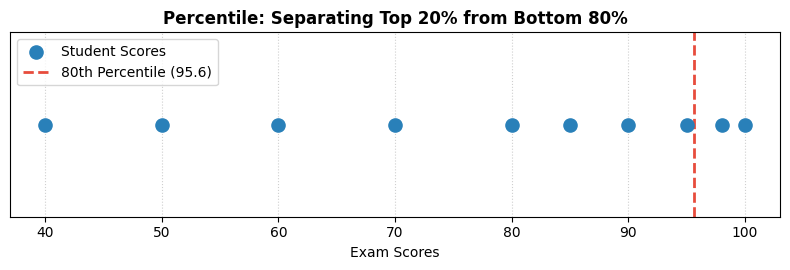

In [4]:
# 1. Percentile Example (80th Percentile)
scores = [40, 50, 60, 70, 80, 85, 90, 95, 98, 100]
p = 80

# Plain Python (Nearest-rank / Interpolation method)
sorted_scores = sorted(scores)
idx = int(np.ceil((p / 100) * len(sorted_scores))) - 1
p80_python = sorted_scores[idx]

# Standard Library (statistics.quantiles - divides into 100 intervals)
# Note: quantiles returns 99 cut points for percentiles
p80_stats = statistics.quantiles(scores, n=100)[79]

# NumPy Library (np.percentile)
p80_np = np.percentile(scores, p)

# SciPy Library (stats.scoreatpercentile)
p80_scipy = stats.scoreatpercentile(scores, p)

print(f"Dataset: {scores}")
print(f"Plain Python (Nearest Rank):  {p80_python}")
print(f"statistics.quantiles(n=100): {p80_stats:.2f}")
print(f"np.percentile():             {p80_np:.2f}")
print(f"scipy scoreatpercentile():   {p80_scipy:.2f}")

# Visualizing 80th Percentile cutoff
plt.figure(figsize=(8, 2.8))
plt.scatter(scores, [1]*len(scores), color='#2980b9', s=90, label='Student Scores', zorder=3)
plt.axvline(p80_np, color='#e74c3c', linestyle='--', lw=2, label=f'80th Percentile ({p80_np:.1f})')
plt.title('Percentile: Separating Top 20% from Bottom 80%', fontweight='bold')
plt.xlabel('Exam Scores')
plt.yticks([])
plt.legend()
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


--- 
## 2. Quartiles & Interquartile Range (Division into 4 Equal Parts)

* **What it does:** Splits sorted data into four quarters: $Q_1$ (25th percentile), $Q_2$ (50th percentile / Median), and $Q_3$ (75th percentile).
* **Mathematical Notation:**
  $$Q_1 = P_{25}, \quad Q_2 = P_{50} = \text{Median}, \quad Q_3 = P_{75}$$
  $$\text{IQR} = Q_3 - Q_1$$
  *Where:*
  * $Q_1$ (*Q one*): First quartile (lower 25% boundary)
  * $Q_2$ (*Q two*): Second quartile (median cut point)
  * $Q_3$ (*Q three*): Third quartile (upper 25% boundary)
  * $\text{IQR}$: Interquartile Range (spread of the middle 50%)
* **Naive Example:** Daily steps in thousands: `[2, 4, 6, 8, 10, 12, 14]` ($n = 7$).
  $$Q_1 = 4, \quad Q_2 = 8, \quad Q_3 = 12, \quad \text{IQR} = 12 - 4 = 8$$
* **When to use:** Boxplot summaries, Tukey's outlier fences ($Q_1 - 1.5\cdot\text{IQR}$, $Q_3 + 1.5\cdot\text{IQR}$).


--- Standard Library (statistics.quantiles) ---
Q1: 4.0, Q2 (Median): 8.0, Q3: 12.0

--- NumPy Library (np.percentile) ---
Q1: 5.0, Q2 (Median): 8.0, Q3: 11.0
IQR (Q3 - Q1): 6.0


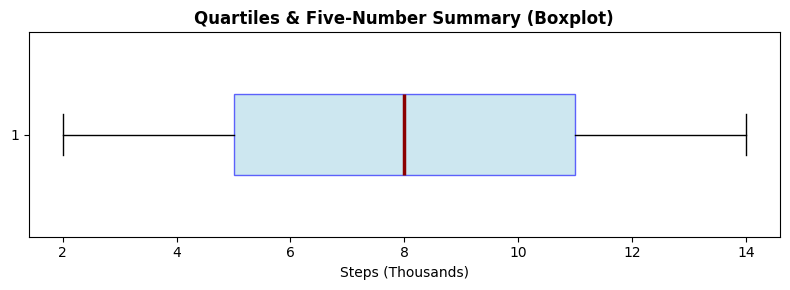

In [6]:
# 2. Quartiles Example
steps = [2, 4, 6, 8, 10, 12, 14]

# Standard Library (statistics.quantiles - splits into 4 parts: Q1, Q2, Q3)
q1_stats, q2_stats, q3_stats = statistics.quantiles(steps, n=4)

# NumPy Library
q1_np, q2_np, q3_np = np.percentile(steps, [25, 50, 75])
iqr_np = q3_np - q1_np

print("--- Standard Library (statistics.quantiles) ---")
print(f"Q1: {q1_stats:.1f}, Q2 (Median): {q2_stats:.1f}, Q3: {q3_stats:.1f}")

print("\n--- NumPy Library (np.percentile) ---")
print(f"Q1: {q1_np:.1f}, Q2 (Median): {q2_np:.1f}, Q3: {q3_np:.1f}")
print(f"IQR (Q3 - Q1): {iqr_np:.1f}")

# Visualization using horizontal Boxplot
fig, ax = plt.subplots(figsize=(8, 3))
bp = ax.boxplot(steps, orientation='horizontal', patch_artist=True, widths=0.4,
                boxprops=dict(facecolor='lightblue', color='blue', alpha=0.6),
                medianprops=dict(color='darkred', linewidth=2.5))
ax.set_title("Quartiles & Five-Number Summary (Boxplot)", fontweight='bold')
ax.set_xlabel("Steps (Thousands)")
plt.tight_layout()
plt.show()


--- 
## 3. Deciles ($D_1$ to $D_9$ - Division into 10 Equal Parts)

* **What it does:** Divides sorted data into **10 equal groups** (10% each).
* **Notation:**
  * $D_1 = P_{10}$ (bottom 10% cutoff)
  * $D_5 = P_{50} = \text{Median}$
  * $D_9 = P_{90}$ (top 10% cutoff)
* **Everyday Application:** Banks divide borrower credit risk into **10 credit deciles** ($D_1$ = lowest risk, $D_{10}$ = highest default risk). Government census divides household wealth into income deciles.


Deciles for Monthly Savings:
  D1 (P10) : ₹ 1550.0
  D2 (P20) : ₹ 2100.0
  D3 (P30) : ₹ 2650.0
  D4 (P40) : ₹ 3200.0
  D5 (P50) : ₹ 3850.0
  D6 (P60) : ₹ 4680.0
  D7 (P70) : ₹ 5700.0
  D8 (P80) : ₹ 7200.0
  D9 (P90) : ₹ 8850.0


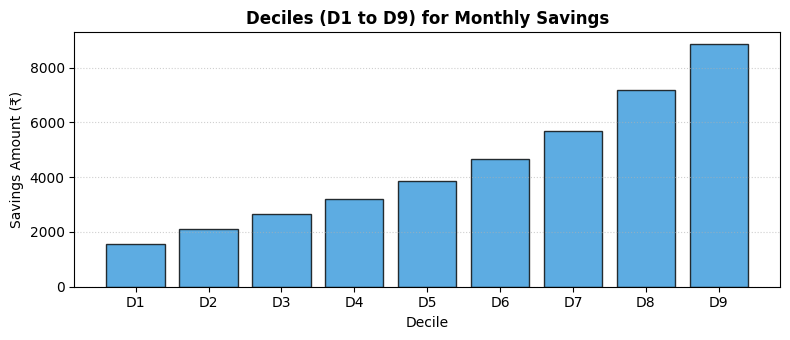

In [8]:
# 3. Deciles (10% slices)
monthly_savings = [1000, 1500, 2000, 2500, 3000, 3500, 4200, 5000, 6000, 7500, 9000, 12000]

# Calculate all 9 deciles (D1 to D9)
deciles = [np.percentile(monthly_savings, d * 10) for d in range(1, 10)]

print("Deciles for Monthly Savings:")
for i, d in enumerate(deciles, 1):
    print(f"  D{i} (P{i*10:2d}) : ₹{d:7.1f}")

# Simple visual plot of Deciles
plt.figure(figsize=(8, 3.5))
plt.bar([f'D{i}' for i in range(1, 10)], deciles, color='#3498db', edgecolor='black', alpha=0.8)
plt.title('Deciles (D1 to D9) for Monthly Savings', fontweight='bold')
plt.xlabel('Decile')
plt.ylabel('Savings Amount (₹)')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


--- 
## 4. $Z$-Score / Standard Score (Distance from Mean in Std Devs)

* **What it does:** Measures how many standard deviations a raw score $x$ lies above or below the sample mean.
* **Mathematical Notation:**
  $$z = \frac{x - \bar{x}}{s} \quad \text{(Sample)} \qquad Z = \frac{x - \mu}{\sigma} \quad \text{(Population)}$$
  *Where:*
  * $z$ (*z-score*): Standardized relative position score
  * $x$ (*x*): Individual data point
  * $\bar{x}$ (*x-bar*): Sample mean
  * $s$ (*s*): Sample standard deviation
* **Naive Example:** An exam score of $x = 85$ in a class where $\bar{x} = 70$ and $s = 10$:
  $$z = \frac{85 - 70}{10} = \frac{15}{10} = +1.50$$
  *(The score is 1.5 standard deviations above the average class performance)*.
* **When to use:** Machine learning feature scaling (StandardScaler), anomaly/outlier detection ($|z| > 3$), and cross-group metric comparisons.


Dataset: [50, 60, 70, 80, 90]
Mean = 70.0, Std Dev = 15.8
Plain Python Z-Score for x=85:     +0.949
SciPy stats.zscore for x=85:       +0.811
NumPy Z-scores for full dataset: [-1.26 -0.63  0.    0.63  1.26]


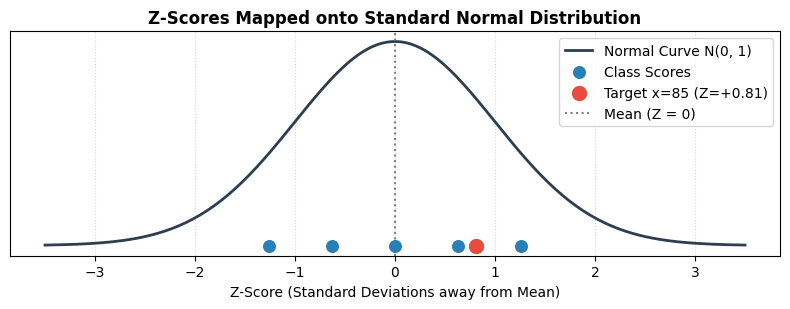

In [10]:
# 4. Z-Score Example
data = [50, 60, 70, 80, 90]
target_val = 85

# Plain Python
mean_val = sum(data) / len(data)
std_val = math.sqrt(sum((x - mean_val) ** 2 for x in data) / (len(data) - 1))
z_python = (target_val - mean_val) / std_val

# SciPy Library (Calculates Z-scores for all elements in array)
# ddof=1 ensures sample standard deviation in denominator
z_array_scipy = stats.zscore(data + [target_val], ddof=1)
z_target_scipy = z_array_scipy[-1]

# NumPy Vectorized Transformation for Entire Dataset
np_data = np.array(data)
z_all_np = (np_data - np.mean(np_data)) / np.std(np_data, ddof=1)

print(f"Dataset: {data}")
print(f"Mean = {mean_val:.1f}, Std Dev = {std_val:.1f}")
print(f"Plain Python Z-Score for x=85:     {z_python:+.3f}")
print(f"SciPy stats.zscore for x=85:       {z_target_scipy:+.3f}")
print(f"NumPy Z-scores for full dataset: {np.round(z_all_np, 2)}")

# Visualizing Z-scores with standard normal curve
x_curve = np.linspace(-3.5, 3.5, 200)
y_curve = stats.norm.pdf(x_curve, 0, 1)

plt.figure(figsize=(8, 3.2))
plt.plot(x_curve, y_curve, color='#2c3e50', lw=2, label='Normal Curve N(0, 1)')
plt.scatter(z_all_np, np.zeros_like(z_all_np), color='#2980b9', s=70, zorder=4, label='Class Scores')
plt.scatter([z_target_scipy], [0], color='#e74c3c', s=100, zorder=5, label='Target x=85 (Z=+0.81)')
plt.axvline(0, color='gray', linestyle=':', label='Mean (Z = 0)')
plt.title('Z-Scores Mapped onto Standard Normal Distribution', fontweight='bold')
plt.xlabel('Z-Score (Standard Deviations away from Mean)')
plt.yticks([])
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


#### Z-Score (Points to Ponder)

A **Z-score** measures how many standard deviations ($\sigma$) a specific data point ($x$) is away from the mean ($\mu$):

$$\text{Z-score} = \frac{x - \mu}{\sigma}$$

---

### What Z-Score Values Mean

| Z-Score | Condition | Interpretation | Location on Bell Curve |
| :--- | :--- | :--- | :--- |
| **Zero ($Z = 0$)** | $x = \mu$ | Data point is **exactly equal to the average** | Dead center |
| **Positive ($Z > 0$)** | $x > \mu$ | Data point is **above/greater than the average** | Right of center |
| **Negative ($Z < 0$)** | $x < \mu$ | Data point is **below/less than the average** | Left of center |

---

### Numerical Examples (Class Mean = 70, Std Dev = 10):
* **Score = 70 ($Z = 0.0$):** $Z = \frac{70 - 70}{10} = \mathbf{0.0}$ *(Exactly average)*
* **Score = 85 ($Z = +1.5$):** $Z = \frac{85 - 70}{10} = \mathbf{+1.5}$ *(1.5 standard deviations above average)*
* **Score = 50 ($Z = -2.0$):** $Z = \frac{50 - 70}{10} = \mathbf{-2.0}$ *(2.0 standard deviations below average)*

---

### Context Matters for Negative Z-Scores:
* **Negative is Desirable:** Software API latency, hospital wait times, golf scores, defect rates.
* **Negative is Undesirable:** Exam marks, sales revenue, battery life, customer satisfaction.


--- 
## 5. Modified $Z$-Score (Robust Outlier Detection with MAD)

* **Why do we need it?**
  * Standard $Z$-score uses **Mean** and **Standard Deviation**.
  * When an extreme outlier is present (e.g. 250°C sensor glitch), it drags the mean way up and inflates the standard deviation!
  * This "hides" or shrinks the Z-scores of other points (known as the **masking effect**).
* **The Solution: Modified $Z$-Score ($M_i$ - Boris Iglewicz & David Hoaglin):**
  Uses the **Median** and **Median Absolute Deviation (MAD)** instead:
  $$M_i = \frac{0.6745 \cdot (x_i - \text{Median})}{\text{MAD}}$$
  *Where $\text{MAD} = \text{median}(|x_i - \text{Median}|)$*
* **Rule of Thumb:** If $|M_i| > 3.5$, the observation is flagged as a **robust outlier**.


Data: [20, 21, 22, 21, 23, 20, 22, 21, 250]
Mean = 46.7°C (Distorted by 250!) | Median = 21.0°C (Completely robust)
-------------------------------------------------------
Value    | Standard Z   | Modified Z   | Modified Flag
-------------------------------------------------------
20       |    -0.35     |    -0.67     | Normal
21       |    -0.34     |    +0.00     | Normal
22       |    -0.32     |    +0.67     | Normal
21       |    -0.34     |    +0.00     | Normal
23       |    -0.31     |    +1.35     | Normal
20       |    -0.35     |    -0.67     | Normal
22       |    -0.32     |    +0.67     | Normal
21       |    -0.34     |    +0.00     | Normal
250      |    +2.67     |  +154.46     | OUTLIER! (|M| > 3.5)


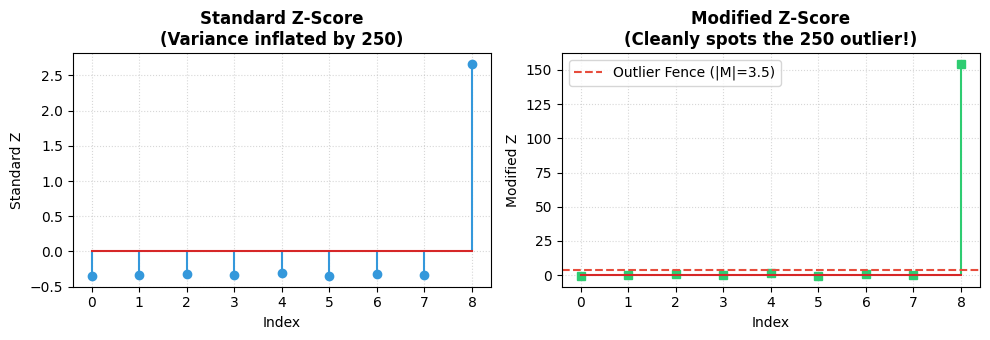

In [13]:
# 5. Modified Z-Score vs. Standard Z-Score with an Outlier
# Notice the massive typing mistake at the end (250°C instead of ~22°C)
temps = [20, 21, 22, 21, 23, 20, 22, 21, 250]

# Standard Z-Score
mean_t = np.mean(temps)
std_t = np.std(temps, ddof=1)
z_standard = [(x - mean_t) / std_t for x in temps]

# Modified Z-Score
med_t = np.median(temps)
mad_t = stats.median_abs_deviation(temps)
z_modified = [0.6745 * (x - med_t) / mad_t for x in temps]

print(f"Data: {temps}")
print(f"Mean = {mean_t:.1f}°C (Distorted by 250!) | Median = {med_t:.1f}°C (Completely robust)")
print("-" * 55)
print(f"{'Value':<8} | {'Standard Z':<12} | {'Modified Z':<12} | {'Modified Flag'}")
print("-" * 55)
for x, sz, mz in zip(temps, z_standard, z_modified):
    flag = "OUTLIER! (|M| > 3.5)" if abs(mz) > 3.5 else "Normal"
    print(f"{x:<8} | {sz:+8.2f}     | {mz:+8.2f}     | {flag}")

# Comparison plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))

ax1.stem(range(len(temps)), z_standard, linefmt='#3498db', markerfmt='o')
ax1.set_title('Standard Z-Score\n(Variance inflated by 250)', fontweight='bold')
ax1.set_xlabel('Index')
ax1.set_ylabel('Standard Z')
ax1.grid(True, linestyle=':', alpha=0.5)

ax2.stem(range(len(temps)), z_modified, linefmt='#2ecc71', markerfmt='s')
ax2.axhline(3.5, color='#e74c3c', linestyle='--', label='Outlier Fence (|M|=3.5)')
ax2.set_title('Modified Z-Score\n(Cleanly spots the 250 outlier!)', fontweight='bold')
ax2.set_xlabel('Index')
ax2.set_ylabel('Modified Z')
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()


--- 
## 6. Percentile Rank (Percentage of Scores At or Below a Value)

* **What it does:** Reverses the percentile operation by calculating what percentage of the dataset falls at or below a specific observation value $x$.
* **Mathematical Notation:**
  $$\text{PR} = \left( \frac{c_L + 0.5 f_E}{n} \right) \times 100$$
  *Where:*
  * $\text{PR}$ (*Percentile Rank*): Percentile rank (0% to 100%)
  * $c_L$ (*count lower*): Total number of values strictly less than $x$
  * $f_E$ (*frequency equal*): Total number of values equal to $x$
  * $n$ (*n*): Total observations
* **Naive Example:** Class test scores: `[50, 60, 70, 70, 80, 90]` ($n = 6$). For score $x = 70$ ($c_L = 2$, $f_E = 2$):
  $$\text{PR} = \left( \frac{2 + 0.5(2)}{6} \right) \times 100 = \frac{3}{6} \times 100 = 50\%$$
* **When to use:** Evaluating candidate rankings in recruitment exams, sports metrics, and clinical benchmarks.


Class Scores: [50, 60, 70, 70, 80, 90]
Target Score: 70
Plain Python Percentile Rank (x=70):  50.0%
SciPy percentileofscore (kind='mean'): 50.0%
SciPy percentileofscore (kind='strict'): 33.3%


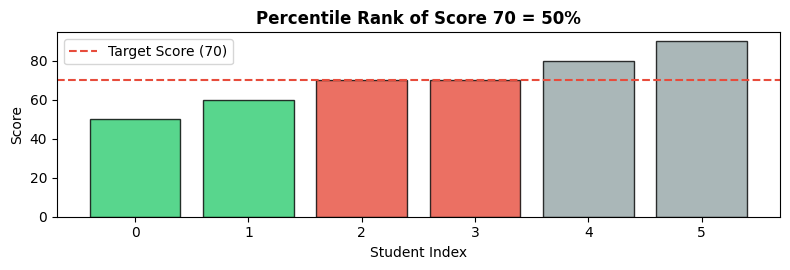

In [15]:
# 6. Percentile Rank Example
scores = [50, 60, 70, 70, 80, 90]
target_score = 70

# Plain Python
count_less = sum(1 for x in scores if x < target_score)
count_equal = sum(1 for x in scores if x == target_score)
pr_python = ((count_less + 0.5 * count_equal) / len(scores)) * 100

# SciPy Library (stats.percentileofscore)
pr_scipy_strict = stats.percentileofscore(scores, target_score, kind='strict') # strict counts < target
pr_scipy_mean = stats.percentileofscore(scores, target_score, kind='mean')     # splits ties (matches formula)

print(f"Class Scores: {scores}")
print(f"Target Score: {target_score}")
print(f"Plain Python Percentile Rank (x=70):  {pr_python:.1f}%")
print(f"SciPy percentileofscore (kind='mean'): {pr_scipy_mean:.1f}%")
print(f"SciPy percentileofscore (kind='strict'): {pr_scipy_strict:.1f}%")

# Visual display
plt.figure(figsize=(8, 2.8))
colors = ['#2ecc71' if s < target_score else ('#e74c3c' if s == target_score else '#95a5a6') for s in scores]
plt.bar(range(len(scores)), scores, color=colors, edgecolor='black', alpha=0.8)
plt.axhline(target_score, color='#e74c3c', linestyle='--', label=f'Target Score ({target_score})')
plt.title(f'Percentile Rank of Score {target_score} = {pr_python:.0f}%', fontweight='bold')
plt.xlabel('Student Index')
plt.ylabel('Score')
plt.legend()
plt.tight_layout()
plt.show()


---
## 7. Master Cheat Sheet & Decision Matrix

| Measure | What it answers | Formula / Function | When to use |
| :--- | :--- | :--- | :--- |
| **Percentile ($P_p$)** | What value separates the bottom $p\%$? | `np.percentile(data, p)` | Competitive exams (CAT, GATE), SLA benchmarks |
| **Quartiles ($Q_1, Q_2, Q_3$)** | Splits data into 4 quarters | `statistics.quantiles(data, n=4)` or `np.percentile(data, [25, 50, 75])` | Boxplots, Five-Number Summary, IQR |
| **Deciles ($D_1 \dots D_9$)** | Splits data into 10 groups | `np.percentile(data, [10, 20, ..., 90])` | Credit risk scoring, customer tiering |
| **$Z$-Score** | How many std deviations away from mean? | $z = \frac{x - \bar{x}}{s}$ or `stats.zscore(data)` | Normal / bell-shaped data, standardized comparisons |
| **Modified $Z$-Score** | Is this value an outlier without being masked? | $M_i = \frac{0.6745(x_i - \text{Median})}{\text{MAD}}$ | Skewed data or data with extreme outliers |
| **Percentile Rank (PR)** | What percentage of data is at or below $x$? | $\text{PR} = \frac{c_L + 0.5 f_E}{n} \times 100$ or `stats.percentileofscore(data, x)` | Reporting personal standing vs. peers |
